(sec-2-3)=
# 2.3 Calculus for Signals

The steepest part of a normal heartbeat is the upstroke of the R wave, where the voltage at the skin rises by about a millivolt in 20 to 30 milliseconds. Most QRS detectors, including the Pan–Tompkins algorithm that we build in Chapter 19, start by computing that slope. Cardiologists, for their part, have long used the *area* of the QRS complex to separate beats that start in the ventricles from normal beats. Slope is a derivative and area is an integral, so even simple ECG processing asks us to differentiate and integrate signals that exist only as lists of samples.

On paper, calculus deals with smooth functions and infinitely small steps. In the computer, every derivative becomes a difference between neighbouring samples and every integral becomes a sum, and these approximations have errors, amplify noise and drift in ways that the textbook formulas do not warn about. In this section I go through the calculus that the rest of the book relies on, always with the sampled version next to the continuous one: finite differences and their accuracy, why differentiation amplifies noise, numerical integration and its drift, the Dirac delta, a short list of integrals that appear again and again, geometric series, and linearization with Taylor's formula. The applied examples use real ECG records from the MIT-BIH Arrhythmia Database.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy import integrate

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-2-3-1)=
## 2.3.1 Derivatives and Finite Differences

The derivative of a signal $x(t)$ is the limit of a difference quotient,

$$
x'(t) = \frac{dx}{dt} = \lim_{h \to 0} \frac{x(t + h) - x(t)}{h}.
$$

A sampled signal $x[n] = x(nT_s)$ does not let us take $h$ smaller than the sampling period $T_s$, so we simply stop at $h = T_s$. Three choices are common:

$$
\underbrace{\frac{x[n+1] - x[n]}{T_s}}_{\text{forward}}, \qquad
\underbrace{\frac{x[n] - x[n-1]}{T_s}}_{\text{backward}}, \qquad
\underbrace{\frac{x[n+1] - x[n-1]}{2T_s}}_{\text{central}}.
$$

The backward difference uses only the present and past samples, so it can run in real time; the forward difference needs the next sample; the central difference needs one future sample and one past sample. To see how accurate each one is, we expand the neighbours of $x(t)$ in Taylor series.

**Step 1: expand the neighbours.** For a smooth signal and $h = T_s$,

$$
\begin{aligned}
x(t + h) &= x(t) + h\,x'(t) + \frac{h^2}{2}x''(t) + \frac{h^3}{6}x'''(t) + \cdots \\
x(t - h) &= x(t) - h\,x'(t) + \frac{h^2}{2}x''(t) - \frac{h^3}{6}x'''(t) + \cdots
\end{aligned}
$$

**Step 2: the forward difference.** Subtracting $x(t)$ from the first line and dividing by $h$,

(eq-2-16)=
\begin{equation*}
\frac{x(t + h) - x(t)}{h} = x'(t) + \frac{h}{2}x''(t) + O(h^2). \tag{2.16}
\end{equation*}

The leading error term is proportional to $h$: halving the step halves the error. We call this a **first-order** approximation. The backward difference has the same error with the opposite sign.

**Step 3: the central difference.** Subtracting the second line from the first, the even-order terms ($x$ and $x''$) cancel, leaving $x(t + h) - x(t - h) = 2h\,x'(t) + \tfrac{h^3}{3}x'''(t) + \cdots$. Dividing by $2h$,

(eq-2-17)=
\begin{equation*}
\frac{x(t + h) - x(t - h)}{2h} = x'(t) + \frac{h^2}{6}x'''(t) + O(h^4). \tag{2.17}
\end{equation*}

Now the error is proportional to $h^2$, so halving the step divides the error by four. This **second-order** accuracy is why `np.gradient` uses the central difference in the interior of an array.

We check both predictions on a Gaussian pulse with a width of 15 ms, roughly the shape of an R wave, evaluated at a point on its upstroke. On a log–log plot, an error proportional to $h^p$ appears as a straight line with slope $p$.

In [2]:
def r_wave(t, amp=1.0, t0=0.0, width=0.015):
    """Gaussian model of an R wave (mV), time in seconds."""
    return amp * np.exp(-0.5 * ((t - t0) / width) ** 2)

def r_wave_slope(t, amp=1.0, t0=0.0, width=0.015):
    """Exact derivative of r_wave (mV/s)."""
    return -(t - t0) / width**2 * r_wave(t, amp, t0, width)

t_eval = -0.01                                         # 10 ms before the peak
steps = np.logspace(-5, -2, 25)                        # step sizes from 10 us to 10 ms
exact = r_wave_slope(t_eval)
err_fwd = np.abs((r_wave(t_eval + steps) - r_wave(t_eval)) / steps - exact)
err_cen = np.abs((r_wave(t_eval + steps) - r_wave(t_eval - steps)) / (2 * steps) - exact)

h = 1 / 360
print(f"exact slope at t = -10 ms : {exact:.2f} mV/s")
print(f"forward, h = 1/360 s      : {(r_wave(t_eval + h) - r_wave(t_eval)) / h:.2f} mV/s")
print(f"central, h = 1/360 s      : {(r_wave(t_eval + h) - r_wave(t_eval - h)) / (2 * h):.2f} mV/s")
slope_f = np.polyfit(np.log10(steps[:10]), np.log10(err_fwd[:10]), 1)[0]
slope_c = np.polyfit(np.log10(steps[:10]), np.log10(err_cen[:10]), 1)[0]
print(f"fitted error slopes: forward {slope_f:.2f}, central {slope_c:.2f}")

exact slope at t = -10 ms : 35.59 mV/s
forward, h = 1/360 s      : 32.33 mV/s
central, h = 1/360 s      : 35.07 mV/s
fitted error slopes: forward 1.00, central 2.00


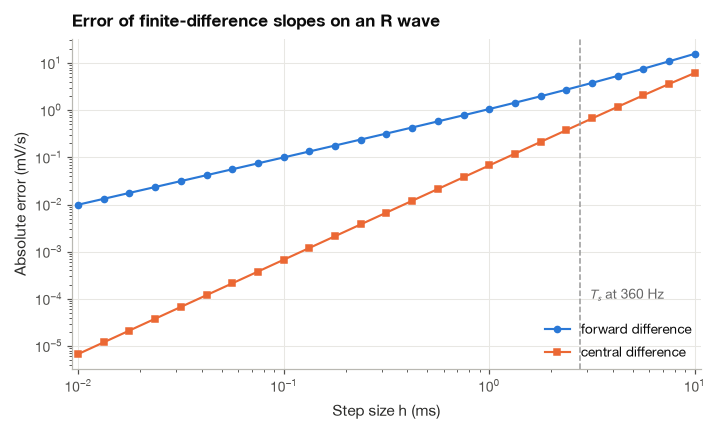

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.loglog(steps * 1000, err_fwd, "o-", color=C[0], ms=4, label="forward difference")
ax.loglog(steps * 1000, err_cen, "s-", color=C[1], ms=4, label="central difference")
ax.axvline(1000 / 360, color="0.6", ls="--", lw=1)
ax.text(1000 / 360 * 1.1, 1e-4, "$T_s$ at 360 Hz", fontsize=9, color="0.4")
ax.set(xlabel="Step size h (ms)", ylabel="Absolute error (mV/s)",
       title="Error of finite-difference slopes on an R wave")
ax.legend(loc="lower right")
plt.show()

The fitted slopes are close to 1 and 2, as equations [(2.16)](#eq-2-16) and [(2.17)](#eq-2-17) predict. At the sampling period of the MIT-BIH records (2.8 ms) the forward difference is off by about 9% on this sharp pulse, the central difference by less than 2%.

(sec-2-3-2)=
## 2.3.2 Differentiation Amplifies Noise

The truncation error above is only half of the story. Real recordings contain noise, and differentiation treats noise very differently from the signal.

The simplest way to see why is to differentiate a sinusoid. For $x(t) = A\cos(\omega t)$, $x'(t) = -A\omega\sin(\omega t)$: the amplitude is multiplied by $\omega = 2\pi f$. A 1 Hz component is multiplied by about 6, a 100 Hz component by about 600. The derivative is a filter whose gain grows linearly with frequency, and since the ECG has most of its energy below 40 Hz while white noise spreads evenly up to $f_s/2$, the derivative tilts the balance toward the noise.

The finite differences behave in the same way, with a twist. Feeding $x[n] = e^{j\Omega n}$ into the backward difference and factoring out $e^{-j\Omega/2}$, as we learned to do with Euler's formula in [Section 2.1](01_complex_numbers.ipynb),

$$
\frac{x[n] - x[n-1]}{T_s} = \frac{1 - e^{-j\Omega}}{T_s}\,e^{j\Omega n} = \frac{e^{-j\Omega/2}\big(e^{j\Omega/2} - e^{-j\Omega/2}\big)}{T_s}\,e^{j\Omega n} = \frac{2j\sin(\Omega/2)}{T_s}\,e^{-j\Omega/2}\,e^{j\Omega n}.
$$

The same manipulation for the central difference gives $(e^{j\Omega} - e^{-j\Omega})/(2T_s) = j\sin(\Omega)/T_s$. So the gains are

(eq-2-18)=
\begin{equation*}
|H_{\text{ideal}}| = \omega = \frac{\Omega}{T_s}, \qquad
|H_{\text{backward}}| = \frac{2\,|\sin(\Omega/2)|}{T_s}, \qquad
|H_{\text{central}}| = \frac{|\sin\Omega|}{T_s}, \tag{2.18}
\end{equation*}

with $\Omega = 2\pi f/f_s$. For small $\Omega$, $\sin\Omega \approx \Omega$ and all three agree. Near the Nyquist frequency they part ways: the backward difference keeps rising to $2/T_s$, while the central difference falls back to zero, because samples two steps apart at the Nyquist frequency are identical. The central difference is a differentiator and a mild low-pass filter at the same time.

We can also count the noise directly. Let $x[n] = s[n] + v[n]$, where $v[n]$ is white noise, meaning that samples are independent with zero mean and variance $\sigma^2$. The noise in the backward difference is $(v[n] - v[n-1])/T_s$, and because the variance of a sum of independent terms is the sum of their variances (proved in [Section 2.4](05_probability_and_statistics.ipynb)),

(eq-2-19)=
\begin{equation*}
\operatorname{Var}\!\left[\frac{v[n] - v[n-1]}{T_s}\right] = \frac{\sigma^2 + \sigma^2}{T_s^2} = \frac{2\sigma^2}{T_s^2}, \qquad
\operatorname{Var}\!\left[\frac{v[n+1] - v[n-1]}{2T_s}\right] = \frac{2\sigma^2}{4T_s^2} = \frac{\sigma^2}{2T_s^2}. \tag{2.19}
\end{equation*}

At 360 Hz, the backward difference multiplies the standard deviation of white noise by $\sqrt{2}\times 360 \approx 509$. We test this on ten seconds of record 100 with 20 µV of white noise added, a level typical of a good ambulatory amplifier.

In [4]:
fs = 360
Ts = 1 / fs
start = 300 * fs
ecg = wfdb.rdrecord("../data/mitdb/100", sampfrom=start, sampto=start + 10 * fs).p_signal[:, 0]
t = np.arange(ecg.size) * Ts
sigma = 0.02                                           # mV
noise = sigma * rng.standard_normal(ecg.size)

def backward_diff(x, Ts):
    """Backward difference (x[n] - x[n-1]) / Ts, first sample repeated."""
    return np.diff(x, prepend=x[0]) / Ts

def central_diff(x, Ts):
    """Central difference (x[n+1] - x[n-1]) / (2 Ts), equation (2.28)."""
    d = np.empty_like(x)
    d[1:-1] = (x[2:] - x[:-2]) / (2 * Ts)
    d[0], d[-1] = (x[1] - x[0]) / Ts, (x[-1] - x[-2]) / Ts
    return d

def snr_db(s, v):
    """Signal-to-noise ratio of signal s and noise v in dB."""
    return 10 * np.log10(np.var(s) / np.var(v))

print(f"central_diff matches np.gradient: {np.allclose(central_diff(ecg, Ts), np.gradient(ecg, Ts))}")
print(f"SNR of the ECG itself            : {snr_db(ecg, noise):5.1f} dB")
for name, D in [("backward", backward_diff), ("central", central_diff)]:
    d_noise = D(ecg + noise, Ts) - D(ecg, Ts)
    pred = np.sqrt(2) * sigma / Ts if name == "backward" else sigma / (np.sqrt(2) * Ts)
    print(f"SNR after {name:8s} difference : {snr_db(D(ecg, Ts), d_noise):5.1f} dB"
          f"   (noise std {d_noise.std():.2f} mV/s, predicted {pred:.2f})")

central_diff matches np.gradient: True
SNR of the ECG itself            :  19.1 dB
SNR after backward difference :   5.6 dB   (noise std 10.00 mV/s, predicted 10.18)
SNR after central  difference :  11.1 dB   (noise std 5.13 mV/s, predicted 5.09)


The SNR falls from about 19 dB to under 6 dB with the backward difference, and the measured noise levels agree with equation [(2.19)](#eq-2-19). The central difference loses less because it rejects the highest frequencies. The figure shows the gains of equation (2.18) and what the loss looks like in the time domain.

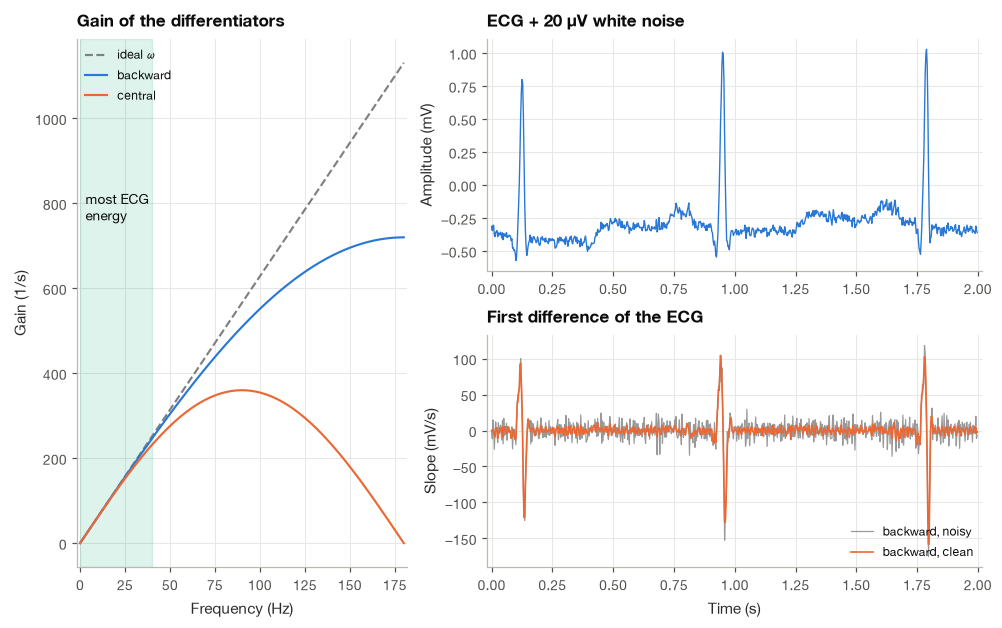

In [5]:
f = np.linspace(0, fs / 2, 400)
Om = 2 * np.pi * f / fs
fig = plt.figure(figsize=(9, 5.6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.5])
ax = fig.add_subplot(gs[:, 0])
ax.plot(f, Om / Ts, color="0.5", ls="--", label=r"ideal $\omega$")
ax.plot(f, 2 * np.abs(np.sin(Om / 2)) / Ts, color=C[0], label="backward")
ax.plot(f, np.abs(np.sin(Om)) / Ts, color=C[1], label="central")
ax.axvspan(0, 40, color=C[2], alpha=0.15)
ax.text(3, 760, "most ECG\nenergy", fontsize=9)
ax.set(xlabel="Frequency (Hz)", ylabel="Gain (1/s)", title="Gain of the differentiators")
ax.legend(loc="upper left", fontsize=8)

sl = slice(0, 2 * fs)
ax1 = fig.add_subplot(gs[0, 1])
ax1.plot(t[sl], ecg[sl] + noise[sl], color=C[0], lw=0.9)
ax1.set(ylabel="Amplitude (mV)", title="ECG + 20 µV white noise")
ax2 = fig.add_subplot(gs[1, 1], sharex=ax1)
ax2.plot(t[sl], backward_diff(ecg + noise, Ts)[sl], color="0.6", lw=0.8, label="backward, noisy")
ax2.plot(t[sl], backward_diff(ecg, Ts)[sl], color=C[1], lw=1.1, label="backward, clean")
ax2.set(xlabel="Time (s)", ylabel="Slope (mV/s)", title="First difference of the ECG")
ax2.legend(loc="lower right", fontsize=8)
plt.show()

The QRS slopes still stand out clearly, which is why derivative-based QRS detectors work, but the flat parts of the trace are now dominated by noise. Detectors therefore low-pass filter the ECG before differentiating, an idea we return to in Section 13.3.

```{note}
Noise amplification depends on *where* the noise lives in frequency. If you repeat the experiment with the real muscle-noise record `nstdb/ma` instead of white noise, the SNR barely changes after differentiation, because muscle noise occupies roughly the same band as the QRS complex and both are amplified by similar amounts. White noise is the worst case because so much of its power sits near the Nyquist frequency.
```

(sec-2-3-3)=
## 2.3.3 Integration: Riemann Sums and the Trapezoid Rule

The definite integral $\int_a^b x(t)\,dt$ is the signed area under the curve. With samples spaced $T_s$ apart, the simplest approximation replaces the curve by rectangles,

$$
\int_a^b x(t)\,dt \approx T_s\sum_{n=0}^{N-1} x[n] \qquad \text{(left Riemann sum)},
$$

where $N = (b - a)/T_s$ and $x[n] = x(a + nT_s)$. Joining neighbouring samples by straight lines instead gives trapezoids, whose areas are $\tfrac{T_s}{2}(x[n] + x[n+1])$. Adding them up, every interior sample appears in two trapezoids and the two end samples in one:

(eq-2-20)=
\begin{equation*}
\int_a^b x(t)\,dt \approx T_s\left(\frac{x[0]}{2} + x[1] + \cdots + x[N-1] + \frac{x[N]}{2}\right). \tag{2.20}
\end{equation*}

The accuracy follows again from Taylor series. Consider one interval of width $h = T_s$ centred at $m$ and write $x(m + s) = x(m) + s\,x'(m) + \tfrac{s^2}{2}x''(m) + \cdots$.

**Step 1: integrate the expansion exactly.** The odd term integrates to zero over the symmetric interval, so

$$
\int_{-h/2}^{h/2} x(m + s)\,ds = h\,x(m) + \frac{x''(m)}{2}\cdot\frac{2}{3}\left(\frac{h}{2}\right)^3 + \cdots = h\,x(m) + \frac{h^3}{24}x''(m) + \cdots
$$

**Step 2: evaluate the trapezoid.** Using the expansion at $s = \pm h/2$, the first-order terms cancel and

$$
\frac{h}{2}\big[x(m - h/2) + x(m + h/2)\big] = h\,x(m) + \frac{h^3}{8}x''(m) + \cdots
$$

**Step 3: subtract and add up.** The trapezoid overestimates one interval by $\big(\tfrac{1}{8} - \tfrac{1}{24}\big)h^3 x'' = \tfrac{h^3}{12}x''$. Summing $N = (b - a)/h$ such errors gives a total error of about

(eq-2-21)=
\begin{equation*}
E_{\text{trap}} \approx \frac{(b - a)\,h^2}{12}\,\overline{x''}, \tag{2.21}
\end{equation*}

where $\overline{x''}$ is the average curvature. The trapezoid rule is second order. A similar calculation for the left Riemann sum leaves an error of about $\tfrac{h}{2}\big(x(a) - x(b)\big)$, first order in $h$. We check both on $\int_0^1 e^{-3t}\,dt = (1 - e^{-3})/3$.

In [6]:
exact = (1 - np.exp(-3)) / 3
rows = []
for N in (10, 20, 40, 80, 160):
    tt = np.linspace(0, 1, N + 1)
    x = np.exp(-3 * tt)
    h = 1 / N
    rows.append({"N": N, "left Riemann error": h * x[:-1].sum() - exact,
                 "trapezoid error": h * (x.sum() - (x[0] + x[-1]) / 2) - exact,
                 "np.trapezoid error": np.trapezoid(x, dx=h) - exact})
print(pd.DataFrame(rows).set_index("N").to_string(float_format="{:.2e}".format))

     left Riemann error  trapezoid error  np.trapezoid error
N                                                           
10             4.99e-02         2.37e-03            2.37e-03
20             2.43e-02         5.94e-04            5.94e-04
40             1.20e-02         1.48e-04            1.48e-04
80             5.98e-03         3.71e-05            3.71e-05
160            2.98e-03         9.28e-06            9.28e-06


Each doubling of $N$ halves the Riemann error and quarters the trapezoid error. NumPy's `np.trapezoid` implements equation [(2.20)](#eq-2-20) and agrees to the last digit.

### Area under a heartbeat

Record 119 of the MIT-BIH database contains long runs of ventricular bigeminy, in which every normal beat is followed by a premature ventricular contraction (PVC). A PVC spreads through the ventricular muscle slowly instead of using the fast conduction system, so its QRS complex is wide and large, and its area is much larger than that of a normal beat. We compute the area of each beat over a fixed window from 60 ms before to 100 ms after the annotated R wave, after subtracting a baseline estimated 90 to 120 ms before the R wave (roughly the PR segment of a normal beat). The unit of area is mV·ms.

In [7]:
fs = 360
rec119 = wfdb.rdrecord("../data/mitdb/119", sampto=10 * 60 * fs)
ann119 = wfdb.rdann("../data/mitdb/119", "atr", sampto=10 * 60 * fs)
ecg119 = rec119.p_signal[:, 0]
sym = np.array(ann119.symbol)

def beat_area(x, r, fs, lo=-0.06, hi=0.10):
    """Trapezoid area (mV*ms) of x from lo to hi seconds around sample r, baseline from the PR segment."""
    base = x[r - int(0.12 * fs):r - int(0.09 * fs)].mean()
    seg = x[r + int(lo * fs):r + int(hi * fs) + 1] - base
    return 1000 * np.trapezoid(seg, dx=1 / fs)

areas = {}
for label in ("N", "V"):
    beats = ann119.sample[(sym == label) & (ann119.sample > 0.2 * fs) & (ann119.sample < ecg119.size - 0.2 * fs)]
    areas[label] = np.array([beat_area(ecg119, r, fs) for r in beats])
    print(f"{label}: {areas[label].size:3d} beats, area {areas[label].mean():6.1f} +/- {areas[label].std():4.1f} mV*ms"
          f"  (range {areas[label].min():.0f} to {areas[label].max():.0f})")

N: 519 beats, area   49.1 +/- 11.2 mV*ms  (range 17 to 66)
V: 140 beats, area  214.2 +/- 12.2 mV*ms  (range 172 to 242)


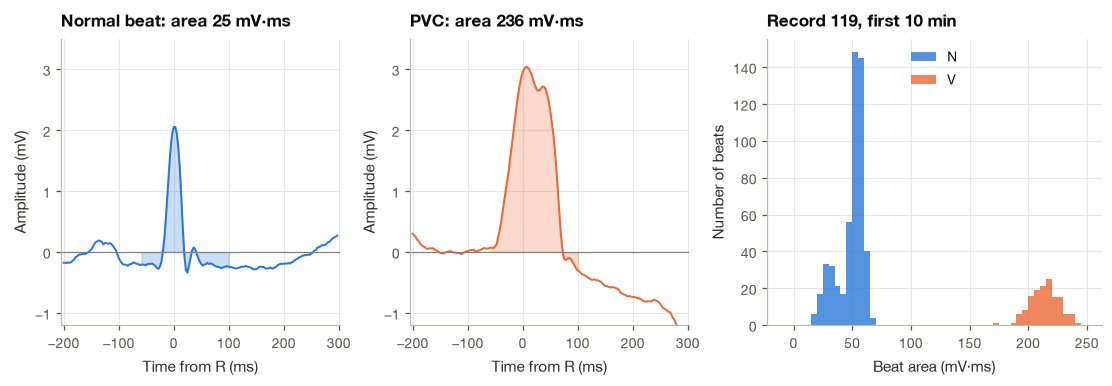

In [8]:
idx_n = ann119.sample[sym == "N"][20]
idx_v = ann119.sample[sym == "V"][20]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1, 1, 1.2]})
for ax, r, lab, col in [(axes[0], idx_n, "Normal beat", C[0]), (axes[1], idx_v, "PVC", C[1])]:
    base = ecg119[r - int(0.12 * fs):r - int(0.09 * fs)].mean()
    tw = np.arange(-int(0.2 * fs), int(0.3 * fs)) / fs
    seg = ecg119[r - int(0.2 * fs):r + int(0.3 * fs)] - base
    ax.plot(tw * 1000, seg, color=col, lw=1.3)
    m = (tw >= -0.06) & (tw <= 0.10)
    ax.fill_between(tw[m] * 1000, seg[m], color=col, alpha=0.25)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set(xlabel="Time from R (ms)", ylabel="Amplitude (mV)", title=f"{lab}: area {beat_area(ecg119, r, fs):.0f} mV·ms",
           ylim=(-1.2, 3.5))
bins = np.linspace(-20, 260, 57)
axes[2].hist(areas["N"], bins=bins, color=C[0], alpha=0.8, label="N")
axes[2].hist(areas["V"], bins=bins, color=C[1], alpha=0.8, label="V")
axes[2].set(xlabel="Beat area (mV·ms)", ylabel="Number of beats", title="Record 119, first 10 min")
axes[2].legend(loc="upper center")
plt.show()

The two histograms do not overlap at all. On this record, a single number computed with the trapezoid rule separates normal beats from PVCs, which is why QRS area remains a standard feature in beat classifiers (Section 19.3). On other patients the separation is less clean, and in Chapter 27 we combine area with other features.

(sec-2-3-4)=
## 2.3.4 Running Integrals and Drift

Often we want the integral as a function of time, $y(t) = \int_0^t x(\tau)\,d\tau$, which in discrete time becomes a running sum $y[n] = T_s\sum_{k=0}^{n} x[k]$ (`np.cumsum` times $T_s$). A clinical example is spirometry: a pneumotachograph measures air flow in litres per second, and the volume of air breathed is its running integral.

The running integral has no way to forget. Any constant offset $b$ in the flow measurement, however small, adds $b\,t$ to the volume, a ramp that grows without limit. Random noise causes a slower but equally unbounded drift. If $v[k]$ is white noise with variance $\sigma^2$, the noise in $y[n]$ is $T_s\sum_{k=0}^{n} v[k]$, a sum of $n + 1$ independent terms, so its variance is

(eq-2-22)=
\begin{equation*}
\operatorname{Var}\big(y_{\text{noise}}[n]\big) = T_s^2\,(n + 1)\,\sigma^2 \quad\Longrightarrow\quad \text{std} = T_s\,\sigma\sqrt{n + 1} = \sigma\sqrt{T_s\,t}. \tag{2.22}
\end{equation*}

The error grows like the square root of time. This is the **random walk**, the opposite behaviour to differentiation: integration attenuates high frequencies (its gain is $1/\omega$) but amplifies very low ones without bound. The simulation below uses quiet breathing at 15 breaths per minute with a tidal volume of 0.5 L, a flow sensor sampled at 100 Hz with 0.02 L/s of white noise, and a zero offset of 0.005 L/s, about 1% of peak flow and well within the calibration error of a real sensor.

In [9]:
fs_r, Ts_r = 100, 0.01
t_r = np.arange(0, 60, Ts_r)
f_br, VT = 15 / 60, 0.5                                 # breathing rate (Hz), tidal volume (L)
volume = VT / 2 * (1 - np.cos(2 * np.pi * f_br * t_r))
flow_true = VT / 2 * 2 * np.pi * f_br * np.sin(2 * np.pi * f_br * t_r)    # dV/dt (L/s)
offset, sigma_f = 0.005, 0.02
flow_meas = flow_true + offset + sigma_f * rng.standard_normal(t_r.size)
vol_est = Ts_r * np.cumsum(flow_meas)

print(f"peak flow: {flow_true.max():.3f} L/s")
print(f"volume error after 60 s: {vol_est[-1] - volume[-1]:+.3f} L  (offset * t = {offset * 60:.3f} L)")

walks = Ts_r * np.cumsum(sigma_f * rng.standard_normal((2000, t_r.size)), axis=1)
print(f"random-walk std at 60 s: {walks[:, -1].std():.4f} L  (equation (2.33): {sigma_f * np.sqrt(Ts_r * 60):.4f} L)")

peak flow: 0.393 L/s
volume error after 60 s: +0.289 L  (offset * t = 0.300 L)


random-walk std at 60 s: 0.0151 L  (equation (2.33): 0.0155 L)


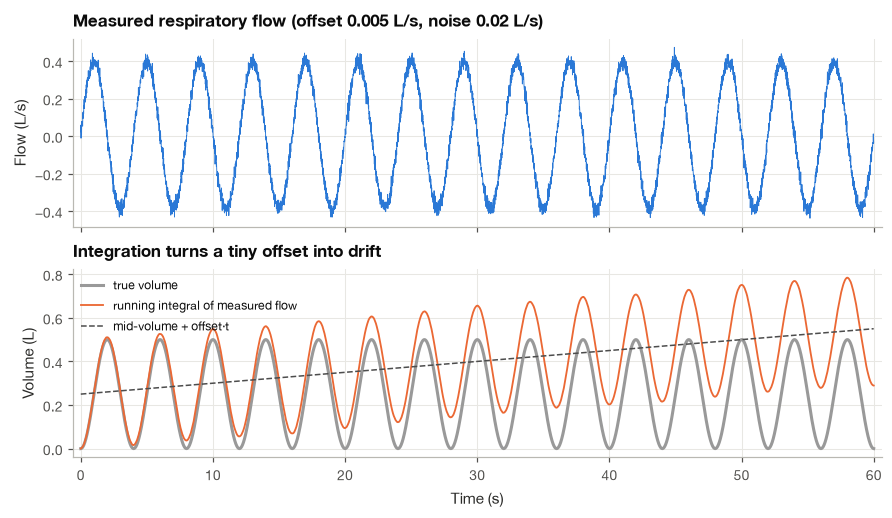

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True)
axes[0].plot(t_r, flow_meas, color=C[0], lw=0.6)
axes[0].set(ylabel="Flow (L/s)", title="Measured respiratory flow (offset 0.005 L/s, noise 0.02 L/s)")
axes[1].plot(t_r, volume, color="0.6", lw=2, label="true volume")
axes[1].plot(t_r, vol_est, color=C[1], lw=1.2, label="running integral of measured flow")
axes[1].plot(t_r, VT / 2 + offset * t_r, color="0.3", ls="--", lw=1, label="mid-volume + offset·t")
axes[1].set(xlabel="Time (s)", ylabel="Volume (L)", title="Integration turns a tiny offset into drift")
axes[1].legend(loc="upper left", fontsize=8)
plt.show()

After one minute the estimated lung volume has drifted by 0.3 L, more than half a tidal breath, even though the flow error is hardly visible. The random walk contributes only about 0.015 L over the same time. Real spirometers correct the offset at every breath, for example by forcing the volume back to the same end-expiratory level, which is a form of high-pass filtering. The same drift appears whenever acceleration is integrated to velocity in wearable motion sensors.

(sec-2-3-5)=
## 2.3.5 The Dirac Delta

The unit impulse $\delta(t)$ was introduced in Section 3.2 and used to build the convolution integral in [Section 4.1](../ch05_convolution/01_impulse_representation.ipynb). It is not an ordinary function, and the cleanest way to work with it is as the limit of ordinary functions. Define a rectangular pulse of width $\varepsilon$ and height $1/\varepsilon$,

(eq-2-23)=
\begin{equation*}
\delta_\varepsilon(t) = \begin{cases} 1/\varepsilon, & |t| < \varepsilon/2, \\ 0, & \text{otherwise,} \end{cases} \qquad \int_{-\infty}^{\infty} \delta_\varepsilon(t)\,dt = 1 \text{ for every } \varepsilon. \tag{2.23}
\end{equation*}

As $\varepsilon \to 0$ the pulse becomes infinitely tall and narrow while its area stays one. The delta is whatever this family tends to *when it sits inside an integral*, which is the only place it ever appears.

**Deriving the sifting property.** Let $x(t)$ be continuous at $t_0$. Multiplying by the shifted pulse and integrating, only the interval where the pulse is non-zero contributes:

$$
\int_{-\infty}^{\infty} x(t)\,\delta_\varepsilon(t - t_0)\,dt = \frac{1}{\varepsilon}\int_{t_0 - \varepsilon/2}^{t_0 + \varepsilon/2} x(t)\,dt .
$$

The right-hand side is the *average* of $x$ over an interval of width $\varepsilon$ centred on $t_0$. By the mean value theorem for integrals, it equals $x(t_\varepsilon)$ for some $t_\varepsilon$ in that interval. As $\varepsilon \to 0$, $t_\varepsilon \to t_0$, and continuity gives $x(t_\varepsilon) \to x(t_0)$. Therefore

(eq-2-24)=
\begin{equation*}
\int_{-\infty}^{\infty} x(t)\,\delta(t - t_0)\,dt = x(t_0). \tag{2.24}
\end{equation*}

Integrating against a delta *samples* the signal. The same limit holds for any family of unit-area pulses that shrink to a point, for example Gaussians of standard deviation $\varepsilon$. I find the averaging interpretation helpful in practice: a real measuring device never samples at a mathematical instant, it averages over a short aperture, and the measured value approaches the true one only when the aperture is short compared with the fastest feature of the signal.

A second property follows by substitution. For $a \neq 0$, put $s = at$ in $\int x(t)\,\delta(at)\,dt$; then $dt = ds/|a|$ (the absolute value accounts for the reversal of the limits when $a < 0$), and the integral becomes $x(0)/|a|$. Hence $\delta(at) = \delta(t)/|a|$, a scaling rule we need for the Fourier transform of sampled signals in [Chapter 6](../ch09_sampling/index.md).

In [11]:
def rect_delta(t, eps):
    """Rectangular nascent delta of width eps, equation (2.34)."""
    return np.where(np.abs(t) < eps / 2, 1 / eps, 0.0)

def gauss_delta(t, eps):
    """Gaussian nascent delta with standard deviation eps."""
    return np.exp(-0.5 * (t / eps) ** 2) / (eps * np.sqrt(2 * np.pi))

tt = np.linspace(-0.3, 0.3, 600_001)                    # 1 us grid
dt = tt[1] - tt[0]
x = r_wave(tt, amp=1.2, width=0.012)                    # 1.2 mV R wave peaking at t0 = 0
rows = []
for eps in (0.1, 0.03, 0.01, 0.003, 0.001):
    rows.append({"eps (ms)": 1000 * eps,
                 "rect sift (mV)": np.trapezoid(x * rect_delta(tt, eps), dx=dt),
                 "Gauss sift (mV)": np.trapezoid(x * gauss_delta(tt, eps), dx=dt)})
print(pd.DataFrame(rows).set_index("eps (ms)").to_string(float_format="{:.4f}".format))
print(f"true value x(0) = {r_wave(0.0, amp=1.2, width=0.012):.4f} mV")

          rect sift (mV)  Gauss sift (mV)
eps (ms)                                 
100.0             0.3609           0.1430
30.0              0.9489           0.4457
10.0              1.1661           0.9219
3.0               1.1965           1.1642
1.0               1.1985           1.1959
true value x(0) = 1.2000 mV


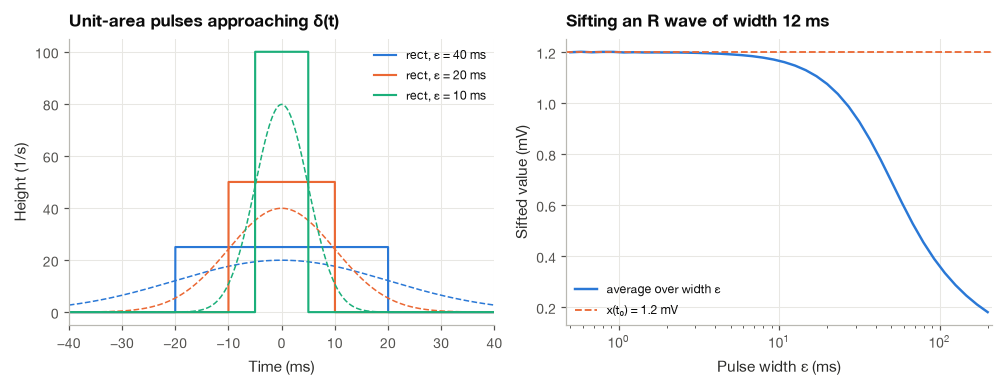

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for k, eps in enumerate((0.04, 0.02, 0.01)):
    axes[0].plot(tt * 1000, rect_delta(tt, eps), color=C[k], lw=1.4, label=f"rect, ε = {1000 * eps:.0f} ms")
    axes[0].plot(tt * 1000, gauss_delta(tt, eps / 2), color=C[k], lw=1, ls="--")
axes[0].set(xlim=(-40, 40), xlabel="Time (ms)", ylabel="Height (1/s)", title="Unit-area pulses approaching δ(t)")
axes[0].legend(loc="upper right", fontsize=8)

eps_grid = np.logspace(-3.3, -0.7, 40)
sift = [np.trapezoid(x * rect_delta(tt, e), dx=dt) for e in eps_grid]
axes[1].semilogx(eps_grid * 1000, sift, color=C[0], lw=1.6, label="average over width ε")
axes[1].axhline(1.2, color=C[1], ls="--", lw=1.2, label="x(t₀) = 1.2 mV")
axes[1].set(xlabel="Pulse width ε (ms)", ylabel="Sifted value (mV)", title="Sifting an R wave of width 12 ms")
axes[1].legend(loc="lower left", fontsize=8)
plt.show()

With a 100 ms aperture the "sample" of the R wave is less than a third of its true height. The value is within 1% of the peak only once $\varepsilon$ falls to a few milliseconds, a fraction of the R wave width.

(sec-2-3-6)=
## 2.3.6 Integrals We Will Use Repeatedly

A handful of integrals appear so often in later chapters (impulse responses, Laplace and Fourier transforms, probability densities) that it pays to derive them once.

**Integration by parts.** Integrating the product rule $(fg)' = f'g + fg'$ from $a$ to $b$ and rearranging,

(eq-2-25)=
\begin{equation*}
\int_a^b f(t)\,g'(t)\,dt = \Big[f(t)\,g(t)\Big]_a^b - \int_a^b f'(t)\,g(t)\,dt. \tag{2.25}
\end{equation*}

The rule trades one integral for another; it helps when $f$ becomes simpler on differentiation.

**Exponentials.** For any constant $a \ne 0$, real or complex, $\int e^{at}\,dt = e^{at}/a + \text{const}$, since differentiating $e^{at}/a$ gives back $e^{at}$. Two special cases matter most. With $a > 0$, the decaying exponential has a finite total area,

$$
\int_0^\infty e^{-at}\,dt = \Big[-\frac{e^{-at}}{a}\Big]_0^\infty = 0 - \Big(-\frac{1}{a}\Big) = \frac{1}{a}.
$$

With $a = j2\pi k/T$ for a non-zero integer $k$, the integral over one period vanishes, $\int_0^T e^{j2\pi k t/T}\,dt = \tfrac{T}{j2\pi k}\big(e^{j2\pi k} - 1\big) = 0$, the continuous counterpart of the orthogonality sums in [Section 2.2.6](03_signals_as_vectors.ipynb#sec-2-2-6).

**Time-weighted exponential.** To compute $\int_0^\infty t\,e^{-at}\,dt$, choose $f = t$ and $g' = e^{-at}$ in equation [(2.25)](#eq-2-25), so $f' = 1$ and $g = -e^{-at}/a$:

(eq-2-26)=
\begin{equation*}
\int_0^\infty t\,e^{-at}\,dt = \Big[-\frac{t\,e^{-at}}{a}\Big]_0^\infty + \frac{1}{a}\int_0^\infty e^{-at}\,dt = 0 + \frac{1}{a}\cdot\frac{1}{a} = \frac{1}{a^2}. \tag{2.26}
\end{equation*}

The boundary term vanishes at infinity because the exponential decays faster than $t$ grows. In the drug-concentration model of [Section 3.1](../ch04_systems/01_what_is_a_system.ipynb), where $C(t) = C_0 e^{-kt}$ after a bolus, the two results give the area under the curve, $\text{AUC} = C_0/k$, and the mean residence time of the drug, $\int t\,C\,dt / \int C\,dt = 1/k$.

**The Gaussian integral.** The integral $I = \int_{-\infty}^{\infty} e^{-t^2}\,dt$ has no elementary antiderivative, but a classic trick computes it exactly.

*Step 1: square it and treat the square as a double integral.* Using different names for the two variables,

$$
I^2 = \int_{-\infty}^{\infty} e^{-u^2}\,du \int_{-\infty}^{\infty} e^{-v^2}\,dv = \iint_{\mathbb{R}^2} e^{-(u^2 + v^2)}\,du\,dv .
$$

*Step 2: change to polar coordinates.* With $u = r\cos\phi$, $v = r\sin\phi$, we have $u^2 + v^2 = r^2$ and the area element $du\,dv$ becomes $r\,dr\,d\phi$. The extra factor $r$ is exactly what makes the integral solvable:

$$
I^2 = \int_0^{2\pi}\!\int_0^\infty e^{-r^2}\,r\,dr\,d\phi = 2\pi\Big[-\tfrac{1}{2}e^{-r^2}\Big]_0^\infty = 2\pi\cdot\frac{1}{2} = \pi .
$$

*Step 3: take the square root and rescale.* Since $I > 0$, $I = \sqrt{\pi}$. Substituting $t = s/(\sigma\sqrt{2})$ then gives the form we need for Gaussian pulses and the normal distribution of [Section 2.4](05_probability_and_statistics.ipynb):

(eq-2-27)=
\begin{equation*}
\int_{-\infty}^{\infty} e^{-t^2}\,dt = \sqrt{\pi}, \qquad \int_{-\infty}^{\infty} e^{-s^2/(2\sigma^2)}\,ds = \sigma\sqrt{2\pi}. \tag{2.27}
\end{equation*}

We confirm all four results with SciPy's adaptive quadrature.

In [13]:
a, sig = 0.35, 0.012
checks = {
    "int_0^inf exp(-a t) dt   = 1/a": (integrate.quad(lambda s: np.exp(-a * s), 0, np.inf)[0], 1 / a),
    "int_0^inf t exp(-a t) dt = 1/a^2": (integrate.quad(lambda s: s * np.exp(-a * s), 0, np.inf)[0], 1 / a**2),
    "int exp(-t^2) dt         = sqrt(pi)": (integrate.quad(lambda s: np.exp(-s**2), -np.inf, np.inf)[0], np.sqrt(np.pi)),
    "int exp(-s^2/2sig^2) ds  = sig sqrt(2pi)": (integrate.quad(lambda s: np.exp(-s**2 / (2 * sig**2)), -1, 1, points=[0])[0],
                                                 sig * np.sqrt(2 * np.pi)),
}
for name, (num, closed) in checks.items():
    print(f"{name:42s} quad = {num:.6f}, closed form = {closed:.6f}")

int_0^inf exp(-a t) dt   = 1/a             quad = 2.857143, closed form = 2.857143
int_0^inf t exp(-a t) dt = 1/a^2           quad = 8.163265, closed form = 8.163265
int exp(-t^2) dt         = sqrt(pi)        quad = 1.772454, closed form = 1.772454
int exp(-s^2/2sig^2) ds  = sig sqrt(2pi)   quad = 0.030080, closed form = 0.030080


(sec-2-3-7)=
## 2.3.7 Geometric Series

Discrete-time systems produce sums of powers, $\sum r^n$, as naturally as continuous systems produce integrals of exponentials. The finite sum has a closed form that we derive with a one-line trick.

**Step 1: write the sum and a shifted copy.** Let $S_N = 1 + r + r^2 + \cdots + r^{N-1}$. Multiplying by $r$ shifts every term one place: $r S_N = r + r^2 + \cdots + r^{N}$.

**Step 2: subtract.** All terms but the first of $S_N$ and the last of $rS_N$ cancel, $S_N - rS_N = 1 - r^N$, so for $r \ne 1$

(eq-2-28)=
\begin{equation*}
\sum_{n=0}^{N-1} r^n = \frac{1 - r^N}{1 - r}, \qquad r \ne 1, \tag{2.28}
\end{equation*}

and $S_N = N$ when $r = 1$. The derivation works for complex $r$, which is how we summed the roots of unity in [Section 2.1](01_complex_numbers.ipynb).

**Step 3: let $N \to \infty$.** If $|r| < 1$, then $|r^N| = |r|^N \to 0$, and

(eq-2-29)=
\begin{equation*}
\sum_{n=0}^{\infty} r^n = \frac{1}{1 - r}, \qquad |r| < 1. \tag{2.29}
\end{equation*}

If $|r| \ge 1$ the terms do not shrink and the series diverges. This single condition, $|r| < 1$, becomes the stability condition for recursive filters in Section 5.5 and, in the language of poles, in Chapter 11.

Differentiating equation (2.29) with respect to $r$ gives one more useful sum, $\sum_{n=0}^\infty n\,r^{n-1} = 1/(1 - r)^2$, so $\sum_{n=0}^\infty n\,r^n = r/(1 - r)^2$. As an application, the exponential smoother of [Section 4.1](../ch05_convolution/01_impulse_representation.ipynb) has impulse response $h[n] = (1 - \alpha)\alpha^n$ for $n \ge 0$. Its total weight is $(1 - \alpha)\cdot\tfrac{1}{1 - \alpha} = 1$, so it passes a constant signal unchanged, and its mean delay is $\sum n\,h[n] = (1 - \alpha)\,\alpha/(1 - \alpha)^2 = \alpha/(1 - \alpha)$ samples.

In [14]:
r, N = 0.9 * np.exp(1j * np.pi / 5), 12
print(f"finite sum, direct  : {np.sum(r ** np.arange(N)):.6f}")
print(f"finite sum, (2.39)  : {(1 - r**N) / (1 - r):.6f}")

alpha, fs_hr = 0.9, 360
n = np.arange(2000)
h = (1 - alpha) * alpha**n
print(f"smoother total weight: {h.sum():.6f}")
print(f"smoother mean delay  : {np.sum(n * h):.4f} samples (alpha/(1-alpha) = {alpha / (1 - alpha):.4f}),"
      f" {1000 * np.sum(n * h) / fs_hr:.1f} ms at 360 Hz")

finite sum, direct  : 1.103121+1.158403j
finite sum, (2.39)  : 1.103121+1.158403j
smoother total weight: 1.000000
smoother mean delay  : 9.0000 samples (alpha/(1-alpha) = 9.0000), 25.0 ms at 360 Hz


(sec-2-3-8)=
## 2.3.8 Taylor Series and Linearization

Taylor's formula, used above to analyse finite differences, has a second job: it lets us replace a nonlinear relationship by a linear one near an operating point. Keeping the first two terms,

(eq-2-30)=
\begin{equation*}
f(x_0 + \Delta) = f(x_0) + f'(x_0)\,\Delta + \frac{f''(\xi)}{2}\,\Delta^2 \approx f(x_0) + f'(x_0)\,\Delta, \tag{2.30}
\end{equation*}

where the remainder term, with $\xi$ between $x_0$ and $x_0 + \Delta$, tells us how large the error of the linear approximation is. Because the remainder is proportional to $\Delta^2$, the relative error of linearization shrinks in proportion to the size of the excursion. Since the systems of [Chapter 3](../ch04_systems/index.md) and everything built on them are linear, this is the step that lets us use linear tools on a nonlinear body.

Photoplethysmography is a good example. The light reaching a PPG photodiode obeys the Beer–Lambert law, $I = I_0\,e^{-A}$, where the absorbance $A$ is proportional to the amount of absorbing material in the light path. With each heartbeat, arterial blood adds a small pulsatile absorbance $\Delta A(t)$ to a large constant absorbance $A_0$ from tissue, venous blood and bone. Expanding the exponential around $A_0$ with equation (2.30), using $\tfrac{d}{dA}e^{-A} = -e^{-A}$,

$$
I(t) = I_0\,e^{-A_0}e^{-\Delta A(t)} \approx \underbrace{I_0\,e^{-A_0}}_{I_{\text{DC}}}\big(1 - \Delta A(t)\big)
\quad\Longrightarrow\quad
\frac{I_{\text{AC}}(t)}{I_{\text{DC}}} \approx -\Delta A(t).
$$

The normalized pulsatile signal is, to first order, a linear and scaled copy of the arterial absorbance change, independent of the LED intensity $I_0$ and of the static tissue. This approximation is the starting point of pulse oximetry (Section 22.1). The pulsatile part of a fingertip PPG is typically 0.5% to 2% of the total, so $\Delta A$ is small and the remainder term predicts an error of about $\Delta A/2$ relative to the AC signal.

In [15]:
dA = np.array([0.005, 0.01, 0.02, 0.05, 0.2])
exact_ratio = np.exp(-dA) - 1                          # I_AC / I_DC, exact
linear_ratio = -dA                                     # first-order Taylor
rel_err = np.abs(linear_ratio - exact_ratio) / np.abs(exact_ratio)
print(pd.DataFrame({"Delta A": dA, "exact AC/DC": exact_ratio, "linear AC/DC": linear_ratio,
                    "relative error (%)": 100 * rel_err}).to_string(index=False, float_format="{:.4f}".format))

 Delta A  exact AC/DC  linear AC/DC  relative error (%)
  0.0050      -0.0050       -0.0050              0.2502
  0.0100      -0.0100       -0.0100              0.5008
  0.0200      -0.0198       -0.0200              1.0033
  0.0500      -0.0488       -0.0500              2.5208
  0.2000      -0.1813       -0.2000             10.3331


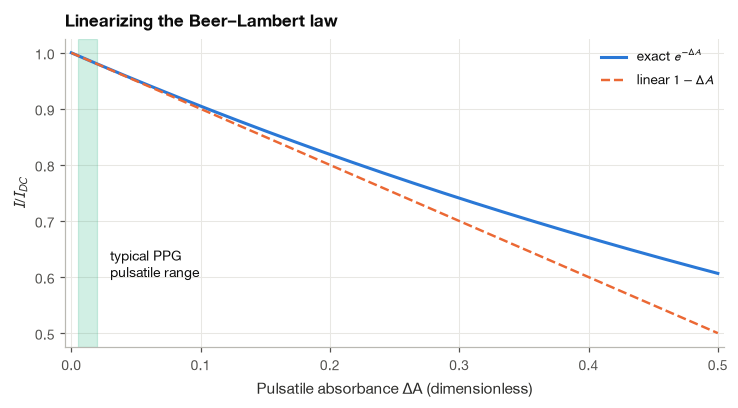

In [16]:
dA_grid = np.linspace(0, 0.5, 300)
fig, ax = plt.subplots(figsize=(6.6, 3.6))
ax.plot(dA_grid, np.exp(-dA_grid), color=C[0], lw=2, label=r"exact $e^{-\Delta A}$")
ax.plot(dA_grid, 1 - dA_grid, color=C[1], lw=1.6, ls="--", label=r"linear $1 - \Delta A$")
ax.axvspan(0.005, 0.02, color=C[2], alpha=0.2)
ax.text(0.03, 0.6, "typical PPG\npulsatile range", fontsize=9)
ax.set(xlabel="Pulsatile absorbance ΔA (dimensionless)", ylabel=r"$I / I_{DC}$",
       title="Linearizing the Beer–Lambert law")
ax.legend(loc="upper right")
plt.show()

In the physiological range the linear and exact curves are indistinguishable, with a relative error of about 1% or less. Only for absorbance changes ten times larger than any real pulse does the curvature start to matter.

## Summary

Calculus on sampled signals replaces limits by finite steps, and Taylor series tell us what that costs. The forward and backward differences are first-order accurate, the central difference second-order, and the trapezoid rule second-order for integration. Differentiation multiplies each frequency by $\omega$, so it boosts the steep QRS complex but also boosts broadband noise: on record 100 with 20 µV of white noise, the backward difference lowered the SNR from about 19 dB to under 6 dB, in agreement with the variance formula $2\sigma^2/T_s^2$. Integration does the reverse, smoothing noise but accumulating offsets into a ramp and noise into a random walk whose spread grows as $\sqrt{t}$. On record 119, the trapezoid area of each beat separated normal beats from PVCs perfectly.

The Dirac delta is best understood as the limit of unit-area pulses, and the sifting property is the statement that a shrinking average samples the signal. Integration by parts, the exponential and Gaussian integrals, and the finite and infinite geometric series will reappear in nearly every derivation of Parts II and III, starting with the convolution integral of Section 5.3, while linearization explains why linear methods work for the PPG and for many other physiological measurements.

## Exercises

1. Derive the second-order central approximation of the second derivative, $x''(t) \approx [x(t + h) - 2x(t) + x(t - h)]/h^2$, from the Taylor expansions in [Section 2.3.1](#sec-2-3-1), and find its leading error term. Verify the order numerically on `r_wave`.
2. Show that the noise variance of the central difference of white noise is $\sigma^2/(2T_s^2)$, then compute the noise gain of the five-point derivative used by Pan and Tompkins, $y[n] = (2x[n] + x[n-1] - x[n-3] - 2x[n-4])/(8T_s)$. Is it larger or smaller than that of the backward difference?
3. Evaluate $\int_0^\infty t^2 e^{-at}\,dt$ by integrating by parts twice, and use the result to compute the variance of the residence time of a drug with elimination rate constant $k$.
4. Use equation (2.28) to prove that a moving average of length $M$ has gain $\left|\sin(M\Omega/2)/(M\sin(\Omega/2))\right|$ for the input $e^{j\Omega n}$. At which frequencies is the gain exactly zero for $M = 7$ at $f_s = 360$ Hz?
5. Repeat the QRS-area experiment of [Section 2.3.3](#sec-2-3-3) on record 208, which contains both PVCs (`V`) and fusion beats (`F`). Plot the three area histograms. Do fusion beats fall between normal beats and PVCs, as their name suggests?
6. Modify the spirometry simulation so that the offset is removed at the end of each expiration (force the volume to the same value at every minimum). Plot the corrected volume over five minutes and estimate the remaining error. What does this correction look like as a filter?

## Further Reading

Finite differences, quadrature and their error analysis are treated clearly in most numerical analysis texts; for the signal-processing view of differentiators and integrators as filters, {cite:t}`lyons2010` and {cite:t}`smith1997` are practical and readable. {cite:t}`lathi2018` covers the impulse function and the integrals needed for transforms with many worked examples. The use of slope and area features for QRS detection and beat classification is discussed in {cite:t}`pan1985`, {cite:t}`sornmo2005` and {cite:t}`rangayyan2015`; the MIT-BIH data are described in {cite:t}`moody2001` and distributed by PhysioNet {cite:p}`goldberger2000`. {cite:t}`allen2007` reviews the physics and physiology of the PPG.